In [9]:
import os
from dotenv import load_dotenv
load_dotenv()
from langchain_groq import ChatGroq
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

model=ChatGroq(model='qwen/qwen3-32b')


In [45]:
from langchain_tavily import TavilySearch

search_tool = TavilySearch(
    max_results=5,
    topic="general"
)

search_tool.invoke("What is new Update on CJP at JanterManter, Dehli ?")

{'query': 'What is new Update on CJP at JanterManter, Dehli ?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.youtube.com/watch?v=qfCA3bYnblA',
   'title': 'CJP Demands Resignation Of Union Minister Dharmendra Pradhan ...',
   'content': 'India Protest: CJP Demands Resignation Of Union Minister Dharmendra Pradhan At Jantar Mantar | WATCH\nMIRROR NOW\n2270000 subscribers\n242 likes\n29248 views\n20 Jun 2026\nDelhi Police has denied permission to Cockroach Janta Party to continue its protest at Jantar Mantar, even as party founder Abhijeet Dipke asserting that he will not move from the site until the education minister resigns. Police have asked CJP supporters to vacate the site where a large number of students and others have been demonstrating over alleged examination irregularities, repeated paper leaks and demands for accountability from the government. \n\nHeavy security arrangements were put in place across the national capital on S

In [23]:
from langchain.tools import tool

@tool("calculator", description="Performs arithmetic calculations, Use this for any math problems.")
def calc(exp: str)->str:
    """Evaluate mathematical expressions"""
    return str(eval(exp))


In [ ]:
from langchain.agents import create_agent
agent = create_agent(model, [search_tool, calc])


<class 'langgraph.graph.state.CompiledStateGraph'>


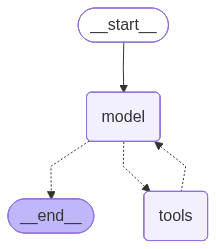

In [42]:
agent

In [46]:
user_input="What is new Update on CJP at JanterManter, Dehli ? and then calculate 47*74"
for step in agent.stream(
    {"messages": user_input},
    stream_mode="values"
):
   step["messages"][-1].pretty_print()

================================ Human Message =================================

What is new Update on CJP at JanterManter, Dehli ? and then calculate 47*74
================================== Ai Message ==================================
Tool Calls:
  tavily_search (r89r5v1xb)
 Call ID: r89r5v1xb
  Args:
    query: new update on CJP at JanterManter, Delhi
    time_range: day
    topic: news
  calculator (e8n8sh9ke)
 Call ID: e8n8sh9ke
  Args:
    exp: 47*74
================================= Tool Message =================================
Name: calculator

3478
================================== Ai Message ==================================

**Latest Updates on CJP Protest at Jantar Mantar, Delhi:**  
The CJP (Cockroach Janata Party) protest, led by activist Sonam Wangchuk, continues at Jantar Mantar. Key developments include:  
- **Political Support:** AAP MP Sanjay Singh and TMC MP Mahua Moitra have joined the protest, demanding the resignation of Union Minister Dharmendra Pradhan.  


In [48]:
res = agent.invoke({"messages": "What is current news in surat? and what is 77-3"})

In [50]:
res['messages'][-1].content

"Here's the information you requested:\n\n**Current News in Surat (July 4, 2026):**\n1. **Tragic Incident:** A child drowned in Surat, sparking local concern.\n2. **Monsoon Challenges:** Heavy rains caused road damage and exposed poor infrastructure quality.\n3. **High Court Ruling:** A significant legal decision impacting the city.\n4. **Flooding Reports:** Areas submerged due to torrential rains, with roads collapsing in some regions.\n\n**Calculation Result:**  \n77 - 3 = **74**  \n\nLet me know if you need more details on any specific news item!"